# Práctica 5 — Normalización 


## Punto 2. Análisis de escalas y detección exploratoria de valores atípicos

**Objetivo de esta sección:** estudiar las unidades, magnitudes, dispersión y valores extremos de las siete mediciones antes de decidir entre normalización Min-Max y Z-score.

**Fuente:** Dataset en `proyecto/data/data-raw/household_power_consumption.txt` Se trabaja con el CSV **limpio** `proyecto/data/data-processed/household_power_consumption_clean.csv`


### 1. Cargar el dataset limpio

El código busca el CSV aunque se ejecute Jupyter desde la raíz del repositorio, desde `proyecto/` o desde `proyecto/notebooks/`. Para evitar duplicar la limpieza, reutilizamos `load_clean_data` y `NUMERIC_COLUMNS`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

NOMBRE_CSV = "household_power_consumption_clean.csv"

# Buscar el dataset sin depender del directorio de trabajo de Jupyter.
ruta_csv = None
for base in (Path.cwd(), *Path.cwd().parents):
    for candidato in (
        base / "proyecto" / "data" / "data-processed" / NOMBRE_CSV,
        base / "data" / "data-processed" / NOMBRE_CSV,
    ):
        if candidato.is_file():
            ruta_csv = candidato.resolve()
            break
    if ruta_csv is not None:
        break

if ruta_csv is None:
    raise FileNotFoundError(
        "No encontré household_power_consumption_clean.csv. "
        "Genera primero el CSV ejecutando proyecto/src/cleaning/preprocessing.py."
    )

proyecto_dir = ruta_csv.parents[2]
sys.path.insert(0, str(proyecto_dir / "src"))
from cleaning.preprocessing import NUMERIC_COLUMNS, load_clean_data

numericas = list(NUMERIC_COLUMNS)
df = load_clean_data(ruta_csv)
print(f"Archivo leído: {ruta_csv}")
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"Periodo: {df['Datetime'].min()} — {df['Datetime'].max()}")
print(f"Columnas numéricas: {numericas}")
display(df.head())

Archivo leído: /home/mirezz/Documentos/Practica5_Norma_PCA/proyecto/data/data-processed/household_power_consumption_clean.csv
Dimensiones: 2,049,280 filas × 8 columnas
Periodo: 2006-12-16 17:24:00 — 2010-11-26 21:02:00
Columnas numéricas: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### 2. Inspeccionar escalas
Esto permite detectar que una variable opera, por ejemplo, cerca de 240 V mientras otra suele encontrarse alrededor de 0.1 kW. **La diferencia de números no implica que una variable sea más importante**: las unidades son distintas.

In [2]:
unidades = {
    "Global_active_power": "kW",
    "Global_reactive_power": "kW (según UCI)",
    "Voltage": "V",
    "Global_intensity": "A",
    "Sub_metering_1": "Wh",
    "Sub_metering_2": "Wh",
    "Sub_metering_3": "Wh",
}

estadisticos = df[numericas]
resumen_escalas = pd.DataFrame({
    "unidad": pd.Series(unidades),
    "minimo": estadisticos.min(),
    "Q25": estadisticos.quantile(0.25),
    "mediana": estadisticos.median(),
    "Q75": estadisticos.quantile(0.75),
    "maximo": estadisticos.max(),
    "rango": estadisticos.max() - estadisticos.min(),
    "media": estadisticos.mean(),
    "desv_estandar": estadisticos.std(),
    "P99": estadisticos.quantile(0.99),
    "porcentaje_ceros": estadisticos.eq(0).mean() * 100,
}).loc[numericas]

display(resumen_escalas.round(3))

,unidad,minimo,Q25,mediana,Q75,maximo,rango,media,desv_estandar,P99,porcentaje_ceros
Global_active_power,kW,0.076,0.308,0.602,1.528,11.122,11.046,1.092,1.057,4.850,0.000
Global_reactive_power,kW (según UCI),0.000,0.048,0.100,0.194,1.390,1.390,0.124,0.113,0.478,23.499
Voltage,V,223.200,238.990,241.010,242.890,254.150,30.950,240.840,3.240,248.270,0.000
Global_intensity,A,0.200,1.400,2.600,6.400,48.400,48.200,4.628,4.444,20.600,0.000
Sub_metering_1,Wh,0.000,0.000,0.000,0.000,88.000,88.000,1.122,6.153,38.000,91.748
Sub_metering_2,Wh,0.000,0.000,0.000,1.000,80.000,80.000,1.299,5.822,36.000,70.114
Sub_metering_3,Wh,0.000,0.000,1.000,17.000,31.000,31.000,6.458,8.437,20.000,41.580


### 3. Detección de posibles valores atípicos mediante IQR
Marcamos un dato como **potencialmente atípico** si cae estrictamente por debajo de `L_inf` o por encima de `L_sup`. Este método es un criterio estadístico de exploración: **no borra ni modifica filas**.

**Advertencia:** si `Q25 = Q75 = 0`, entonces `IQR = 0` y todo valor distinto de cero queda marcado. Esto ocurre con variables con muchos ceros, como `Sub_metering_1`; en ese caso, el criterio puede ser poco informativo para detectar anomalías reales.

In [3]:
q25 = estadisticos.quantile(0.25)
q75 = estadisticos.quantile(0.75)
iqr = q75 - q25
limite_inferior = q25 - 1.5 * iqr
limite_superior = q75 + 1.5 * iqr

# Comparación vectorizada, columna por columna.
es_atipico = estadisticos.lt(limite_inferior) | estadisticos.gt(limite_superior)

resumen_atipicos = pd.DataFrame({
    "Q25": q25,
    "Q75": q75,
    "IQR": iqr,
    "limite_inferior": limite_inferior,
    "limite_superior": limite_superior,
    "cantidad_atipicos": es_atipico.sum().astype(int),
    "porcentaje_atipicos": es_atipico.mean() * 100,
    "IQR_igual_a_cero": iqr.eq(0),
}).loc[numericas]

display(resumen_atipicos.round(3))
print("Nota: con IQR=0, algunos valores habituales pueden ser marcados como atípicos.")

,Q25,Q75,IQR,limite_inferior,limite_superior,cantidad_atipicos,porcentaje_atipicos,IQR_igual_a_cero
Global_active_power,0.308,1.528,1.220,-1.522,3.358,94907,4.631,False
Global_reactive_power,0.048,0.194,0.146,-0.171,0.413,40420,1.972,False
Voltage,238.990,242.890,3.900,233.140,248.740,51067,2.492,False
Global_intensity,1.400,6.400,5.000,-6.100,13.900,100961,4.927,False
Sub_metering_1,0.000,0.000,0.000,0.000,0.000,169105,8.252,True
Sub_metering_2,0.000,1.000,1.000,-1.500,2.500,77151,3.765,False
Sub_metering_3,0.000,17.000,17.000,-25.500,42.500,0,0.000,False


Nota: con IQR=0, algunos valores habituales pueden ser marcados como atípicos.


Observamos que algunas variables presentan límites inferiores negativos. Esto se debe a la fórmula utilizada para calcular el IQR y no significa que existan mediciones negativas de consumo eléctrico.

En las variables de consumo, donde los valores no pueden ser negativos, podemos considerar que las mediciones esperadas parten de cero. Por lo tanto, cuando el límite inferior calculado es negativo, los valores atípicos se identificarían principalmente al superar el límite superior.

Sin embargo, existen variables como `Voltage`, cuyo límite inferior es positivo, por lo que también podemos encontrar valores atípicos por debajo de este límite.

Es importante considerar que un valor atípico no necesariamente representa un error, sino que puede ser una medición inusual que debemos analizar.

### 4. Visualización: boxplots individuales
Como las siete variables tienen escalas y unidades distintas, usamos **un gráfico por variable**, cada uno con su propio eje. Para no dibujar millones de puntos, ocultamos los símbolos individuales de atípicos (`showfliers=False`). **La detección de atípicos sí se hizo con todas las filas**, y sus cantidades aparecen en la tabla anterior.

/tmp/ipykernel_12539/2959557151.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(estadisticos[variable].to_numpy(), vert=False, showfliers=False)
/tmp/ipykernel_12539/2959557151.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(estadisticos[variable].to_numpy(), vert=False, showfliers=False)
/tmp/ipykernel_12539/2959557151.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eje.boxplot(estadisticos[variable].to_numpy(), vert=False, showfliers=False)
/tmp/ipykernel_12539/2959557151.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horiz

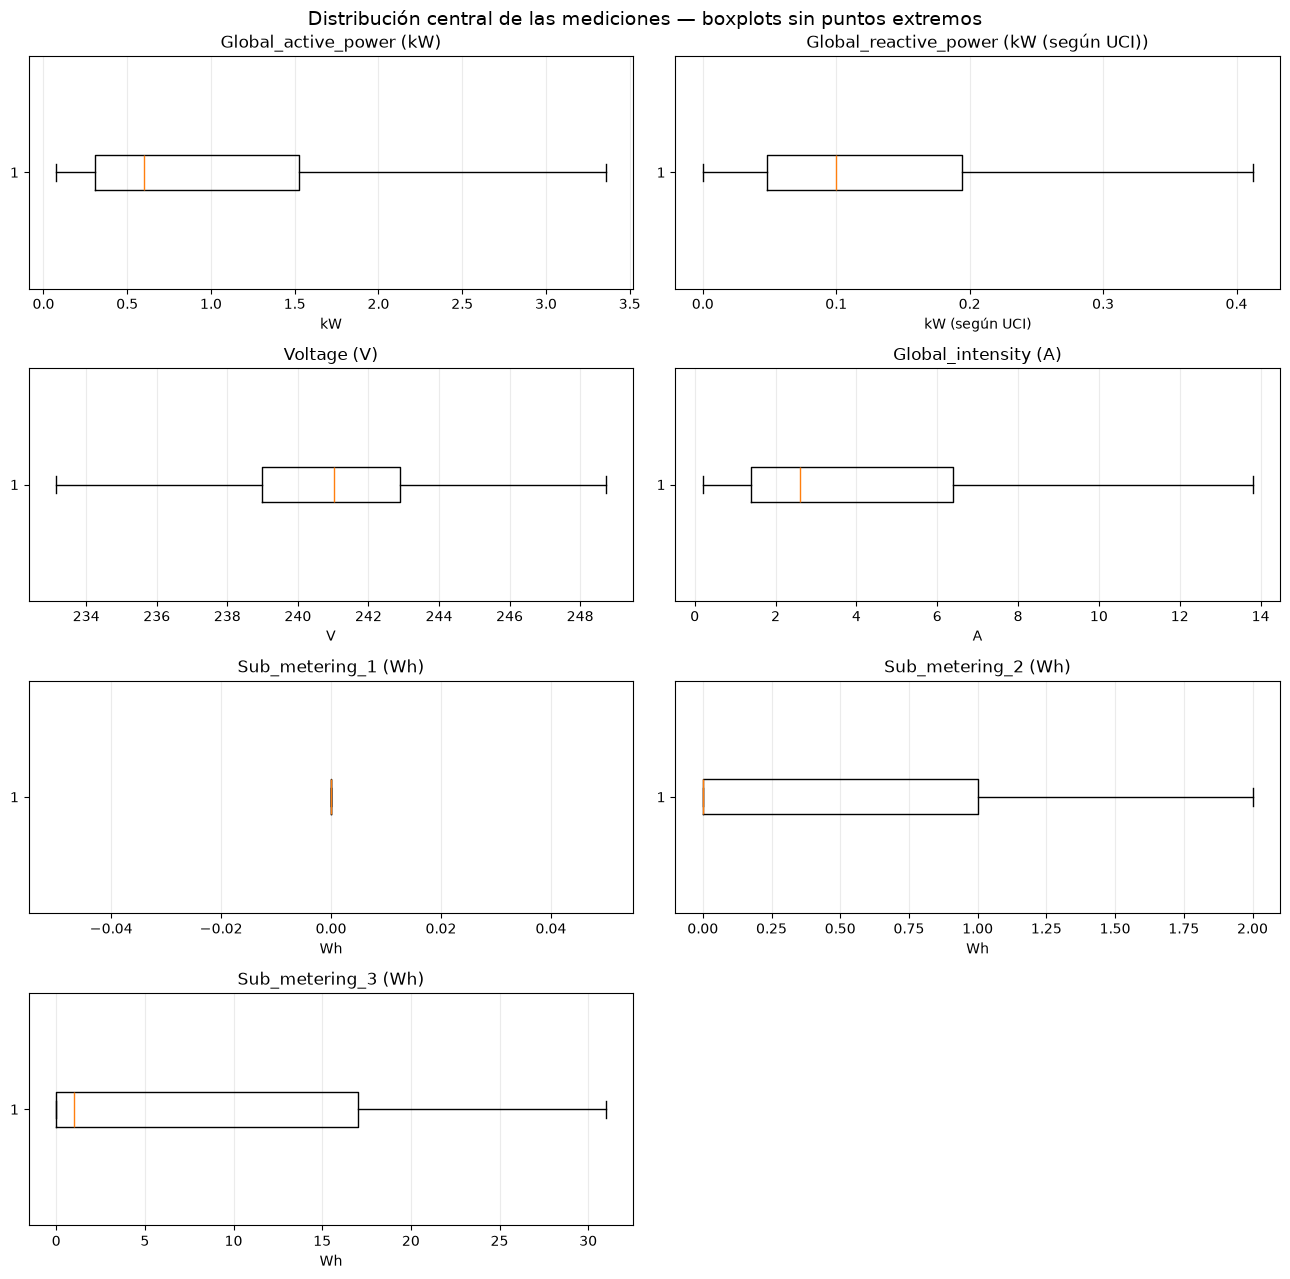

In [4]:
fig, ejes = plt.subplots(4, 2, figsize=(13, 13))
for eje, variable in zip(ejes.flat, numericas):
    eje.boxplot(estadisticos[variable].to_numpy(), vert=False, showfliers=False)
    eje.set_title(f"{variable} ({unidades[variable]})")
    eje.set_xlabel(unidades[variable])
    eje.grid(axis="x", alpha=0.25)

for eje in list(ejes.flat)[len(numericas):]:
    eje.axis("off")

fig.suptitle("Distribución central de las mediciones — boxplots sin puntos extremos", fontsize=14)
fig.tight_layout()
plt.show()

---
## Paso 3 de la práctica: normalización numérica con Z-score

### 7. Elección del método y control temporal

Utilizaremos **Z-score** para poner las variables numéricas en escalas comparables: media 0 y desviación estándar poblacional 1 **en el entrenamiento**.

**Justificación:** algunas mediciones tienen magnitudes muy distintas y existen posibles valores extremos. Min-Max puede comprimir la mayoría de los valores en una parte pequeña del rango si aparecen extremos muy alejados. Z-score centra cada variable y facilita el PCA posterior; **también es sensible a los valores atípicos** y no los elimina.


In [5]:
from sklearn.preprocessing import StandardScaler

# El CSV limpio ya fue cargado anteriormente en `df`.
# `numericas` contiene las siete mediciones; Datetime se excluye.
fecha_corte = pd.Timestamp("2010-01-01")
df = df.sort_values("Datetime").reset_index(drop=True)

mascara_entrenamiento = df["Datetime"] < fecha_corte
mascara_prueba = ~mascara_entrenamiento

if not mascara_entrenamiento.any() or not mascara_prueba.any():
    raise ValueError("La fecha de corte debe dejar registros de entrenamiento y prueba.")

print(f"Entrenamiento: {mascara_entrenamiento.sum():,} registros")
print(f"Prueba:        {mascara_prueba.sum():,} registros")
print(f"Último entrenamiento: {df.loc[mascara_entrenamiento, 'Datetime'].max()}")
print(f"Primera prueba:       {df.loc[mascara_prueba, 'Datetime'].min()}")

Entrenamiento: 1,591,886 registros
Prueba:        457,394 registros
Último entrenamiento: 2009-12-31 23:59:00
Primera prueba:       2010-01-01 00:00:00


### 8. Ajustar y aplicar Z-score

`fit()` **aprende** la media y la desviación estándar de cada variable **solo con entrenamiento**. `transform()` usa esos parámetros tanto en entrenamiento como en prueba, sin volver a ajustarlos.

Con `StandardScaler`, `scale_` utiliza la desviación estándar poblacional (`ddof=0`), por lo que puede diferir ligeramente del `std()` predeterminado en pandas (`ddof=1`).

In [6]:
escalador = StandardScaler()

# ÚNICA llamada a fit: únicamente datos de entrenamiento.
escalador.fit(df.loc[mascara_entrenamiento, numericas])

# Aplicamos la misma transformación a todo el periodo.
# La prueba nunca interviene en el cálculo de los parámetros.
df_zscore = df[["Datetime"]].copy()
df_zscore[numericas] = escalador.transform(df[numericas])

display(df_zscore.head())
print("¿Se conservó Datetime?:", df_zscore["Datetime"].equals(df["Datetime"]))
print("¿Se conservaron las filas?:", len(df_zscore) == len(df))

,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,2.857736,2.641943,-1.749768,2.994735,-0.184404,-0.059039,1.289969
1,2006-12-16 17:25:00,3.907056,2.802641,-2.114446,3.998119,-0.184404,-0.059039,1.170164
2,2006-12-16 17:26:00,3.919897,3.356158,-2.216918,3.998119,-0.184404,0.107234,1.289969
3,2006-12-16 17:27:00,3.932739,3.391869,-2.081294,3.998119,-0.184404,-0.059039,1.289969
4,2006-12-16 17:28:00,2.353255,3.623988,-1.496603,2.427606,-0.184404,-0.059039,1.289969


¿Se conservó Datetime?: True
¿Se conservaron las filas?: True


### 9. Verificación e interpretación

Comprobamos que las siete variables tengan media aproximadamente cero y desviación estándar aproximadamente uno en el **entrenamiento**. La prueba puede tener otros valores: es lo esperado si cambia el comportamiento temporal de las mediciones.

In [7]:
resumen_zscore = pd.DataFrame({
    "media_original_entrenamiento": escalador.mean_,
    "desv_original_entrenamiento": escalador.scale_,
    "media_z_entrenamiento": df_zscore.loc[mascara_entrenamiento, numericas].mean().to_numpy(),
    "desv_z_entrenamiento": df_zscore.loc[mascara_entrenamiento, numericas].std(ddof=0).to_numpy(),
    "media_z_prueba": df_zscore.loc[mascara_prueba, numericas].mean().to_numpy(),
}, index=numericas)

display(resumen_zscore.round(5))

# Se esperan estos valores en entrenamiento, no necesariamente en prueba.
assert np.allclose(resumen_zscore["media_z_entrenamiento"], 0, atol=1e-10)
assert np.allclose(resumen_zscore["desv_z_entrenamiento"], 1, atol=1e-10)
assert df_zscore["Datetime"].equals(df["Datetime"])
assert not df_zscore[numericas].isna().any().any()
print("Validaciones de estandarización superadas.")

,media_original_entrenamiento,desv_original_entrenamiento,media_z_entrenamiento,desv_z_entrenamiento,media_z_prueba
Global_active_power,1.10041,1.09023,-0.0,1.0,-0.03615
Global_reactive_power,0.12207,0.11201,-0.0,1.0,0.06566
Voltage,240.64572,3.31799,-0.0,1.0,0.26215
Global_intensity,4.67067,4.58449,-0.0,1.0,-0.04193
Sub_metering_1,1.16054,6.29346,-0.0,1.0,-0.02749
Sub_metering_2,1.35507,6.01422,-0.0,1.0,-0.04213
Sub_metering_3,6.23273,8.34693,0.0,1.0,0.12116


Validaciones de estandarización superadas.


### 10. Guardar la versión estandarizada (sin sobrescribir la limpia)

Los resultados se guardan dentro de `data/data-processed/`. El archivo original y el CSV limpio permanecen intactos.

La tabla de parámetros documenta la media, desviación estándar y fecha de corte utilizadas. Esto permite reproducir la transformación y explicar las decisiones en el README.

In [8]:
ruta_salida = ruta_csv.with_name("household_power_consumption_zscore.csv")
ruta_parametros = ruta_csv.with_name("zscore_parametros.csv")

parametros_zscore = pd.DataFrame({
    "variable": numericas,
    "media_entrenamiento": escalador.mean_,
    "desviacion_entrenamiento": escalador.scale_,
    "fecha_corte_exclusiva": str(fecha_corte.date()),
    "registros_entrenamiento": int(mascara_entrenamiento.sum()),
    "registros_prueba": int(mascara_prueba.sum()),
})

# Ambos CSV usan ; para ser consistentes con el preprocesamiento.
df_zscore.to_csv(ruta_salida, sep=";", index=False)
parametros_zscore.to_csv(ruta_parametros, sep=";", index=False)
print(f"Dataset estandarizado guardado en: {ruta_salida}")
print(f"Parámetros guardados en: {ruta_parametros}")
display(parametros_zscore)

Dataset estandarizado guardado en: /home/mirezz/Documentos/Practica5_Norma_PCA/proyecto/data/data-processed/household_power_consumption_zscore.csv
Parámetros guardados en: /home/mirezz/Documentos/Practica5_Norma_PCA/proyecto/data/data-processed/zscore_parametros.csv


,variable,media_entrenamiento,desviacion_entrenamiento,fecha_corte_exclusiva,registros_entrenamiento,registros_prueba
0,Global_active_power,1.100412,1.090230,2010-01-01,1591886,457394
1,Global_reactive_power,0.122073,0.112011,2010-01-01,1591886,457394
2,Voltage,240.645719,3.317994,2010-01-01,1591886,457394
3,Global_intensity,4.670667,4.584489,2010-01-01,1591886,457394
4,Sub_metering_1,1.160541,6.293462,2010-01-01,1591886,457394
5,Sub_metering_2,1.355073,6.014221,2010-01-01,1591886,457394
6,Sub_metering_3,6.232729,8.346925,2010-01-01,1591886,457394
